In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
from matplotlib import pyplot as plt
import netCDF4
import xarray as xr

In [27]:
#数据读取
df = pd.read_csv("Sig_Eqs.tsv", sep="\t")

In [28]:
#1.1
#数据清洗，提高鲁棒性
df["Total Deaths"] = pd.to_numeric(df["Total Deaths"], errors="coerce")
res = df.groupby("Country")["Total Deaths"].sum().sort_values(ascending=False).head(20)
print(res)

Country
CHINA           2106526.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
GREECE            83658.0
PORTUGAL          82572.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0
Name: Total Deaths, dtype: float64


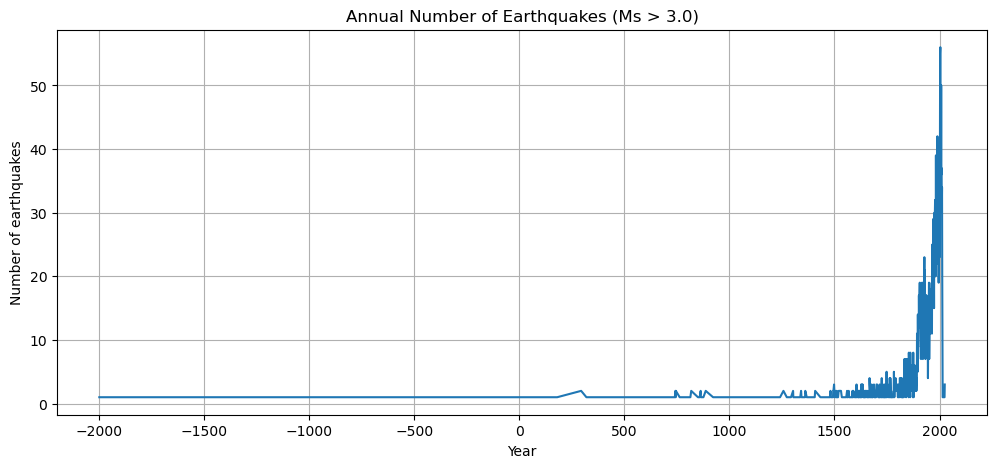

In [29]:
#1.2
#数据清洗删除年份或震级缺失的数据
df3 = df.dropna(subset=["Year", "Ms"])
df3 = df3[df3["Ms"] > 3.0]

# 根据结果优化了表格尺寸增加了表格标题等
df3.groupby("Year").size().sort_index().plot(
    figsize=(12, 5), xlabel="Year", ylabel="Number of earthquakes",
    title="Annual Number of Earthquakes (Ms > 3.0)", grid=True
)
plt.show()

#根据结果可观测到地震记录整体呈上升趋势尤其是1500年之后接近2000年时涨幅非常明显，可能是由于接近现代地震监测技术的上升和数据统计更加完善但也不排除地震频率确实在上升的可能

In [30]:
#1.3
# 定义函数：统计地震总数，并返回最大地震的日期和地点
def CountEq_LargestEq(data):
    # 统计该国家的地震总数
    total = len(data)
    # 找出有震级记录的地震
    valid = data.dropna(subset=["Mag"])

    # 如果该国家没有有效震级记录则返回结果防止报错
    if valid.empty:
        return pd.Series({
            "Total Earthquakes": total,
            "Largest Earthquake Date": "Unknown",
            "Largest Earthquake Location": "Unknown"
        })

    # 找到最大震级
    max_ms = valid["Mag"].max()
    largest = valid.loc[valid["Mag"] == max_ms].iloc[0]

    # 输出最大地震的日期
    if pd.notna(largest["Mo"]) and pd.notna(largest["Dy"]):
        date = (
            f'{int(largest["Year"])}-'
            f'{int(largest["Mo"]):02d}-'
            f'{int(largest["Dy"]):02d}'
        )
    #如果月日信息缺失
    else:
        date = str(int(largest["Year"]))

    return pd.Series({
        "Total Earthquakes": total,
        "Largest Earthquake Date": date,
        "Largest Earthquake Location": largest["Location Name"]
    })

#调用函数并降序输出结果
result = df.groupby("Country").apply(
    CountEq_LargestEq,
    include_groups=False
).sort_values("Total Earthquakes", ascending=False)

display(result)

,Total Earthquakes,Largest Earthquake Date,Largest Earthquake Location
Country,,,
CHINA,626,1668-07-25,CHINA: SHANDONG PROVINCE
JAPAN,429,2011-03-11,JAPAN: HONSHU
INDONESIA,427,2004-12-26,INDONESIA: SUMATRA: ACEH: OFF WEST COAST
IRAN,385,856-12-22,"IRAN: DAMGHAN, QUMIS"
TURKEY,359,1939-12-26,TURKEY: ERZINCAN
...,...,...,...
SRI LANKA,1,Unknown,Unknown
MONTSERRAT,1,Unknown,Unknown
PALAU,1,1914-10-23,"MICRONESIA, FED. STATES OF: CAROLINE ISLANDS"


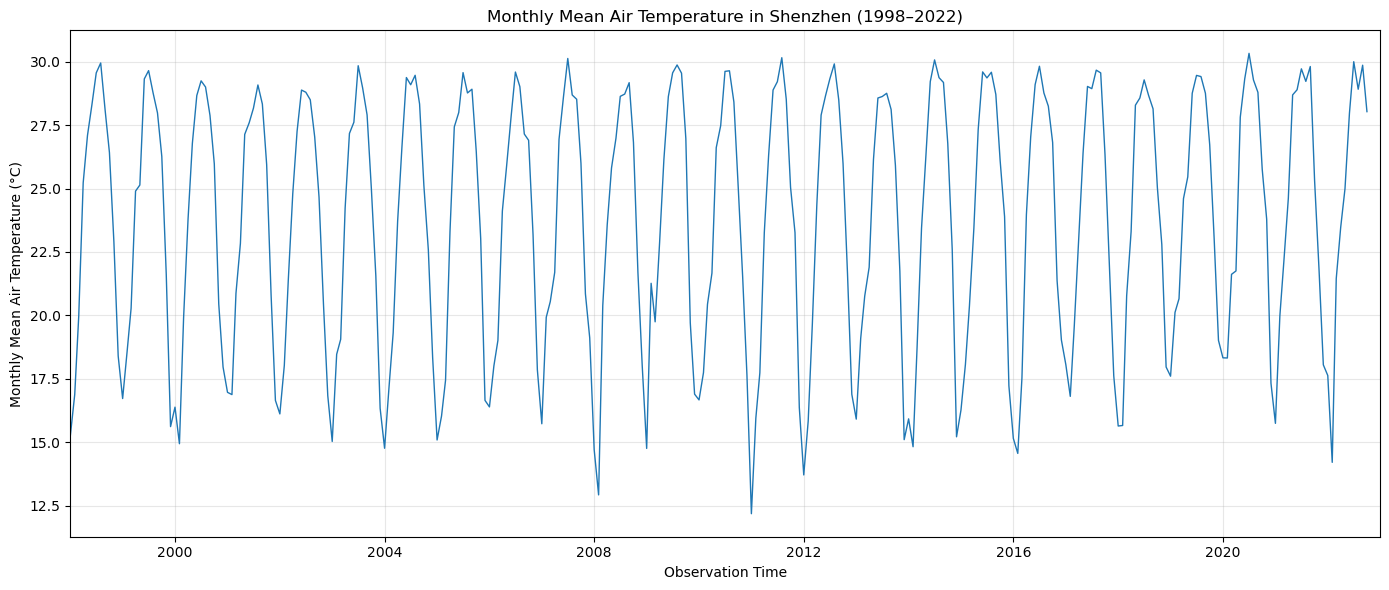

In [32]:
#2深圳气温

#筛选数据方法在报告中详解

# 读取气象数据
weather_data = pd.read_csv(
    "Baoan_Weather_1998_2022.csv",
    low_memory=False
)

# 清洗时间数据
weather_data["DATE"] = pd.to_datetime(
    weather_data["DATE"], errors="coerce"
)

# 拆分TMP字段，分别提取气温值和质量标记
temperature_parts = (
    weather_data["TMP"]
    .astype("string")
    .str.split(",", expand=True)
)

weather_data["temperature_code"] = pd.to_numeric(
    temperature_parts[0], errors="coerce"
)

weather_data["quality_flag"] = temperature_parts[1]

# 将气温原始值转换为摄氏度
weather_data["air_temp_celsius"] = (
    weather_data["temperature_code"] / 10
)

# 筛选有效气温记录
clean_weather = weather_data[
    weather_data["DATE"].notna()
    & weather_data["temperature_code"].notna()
    & (weather_data["temperature_code"] != 9999)
    & weather_data["quality_flag"].isin(["1", "5"])
].copy()

# 限定研究时间
clean_weather = clean_weather[
    (clean_weather["DATE"] >= "1998-01-01")
    & (clean_weather["DATE"] < "2023-01-01")
]

# 计算每月平均气温
clean_weather = clean_weather.set_index("DATE")
monthly_average = (
    clean_weather["air_temp_celsius"]
    .resample("MS")
    .mean()
)

# 绘制月平均气温时间序列
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_average.index,
    monthly_average.values,
    linewidth=1
)

plt.title("Monthly Mean Air Temperature in Shenzhen (1998–2022)")
plt.xlabel("Observation Time")
plt.ylabel("Monthly Mean Air Temperature (°C)")

plt.xlim(
    pd.Timestamp("1998-01-01"),
    pd.Timestamp("2022-12-31")
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


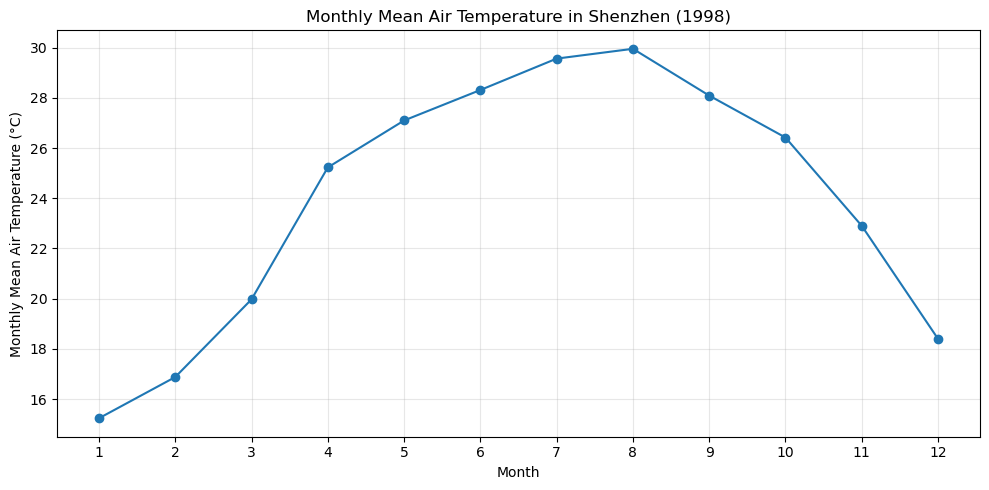

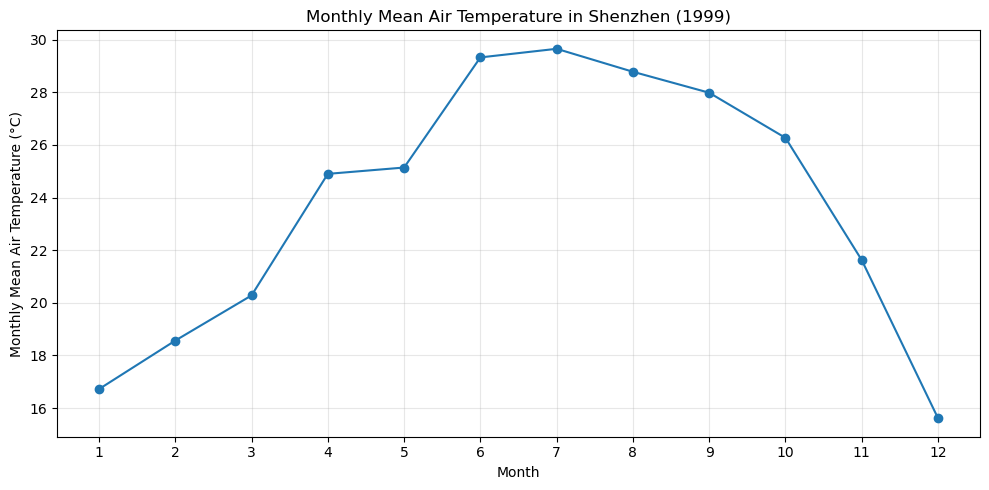

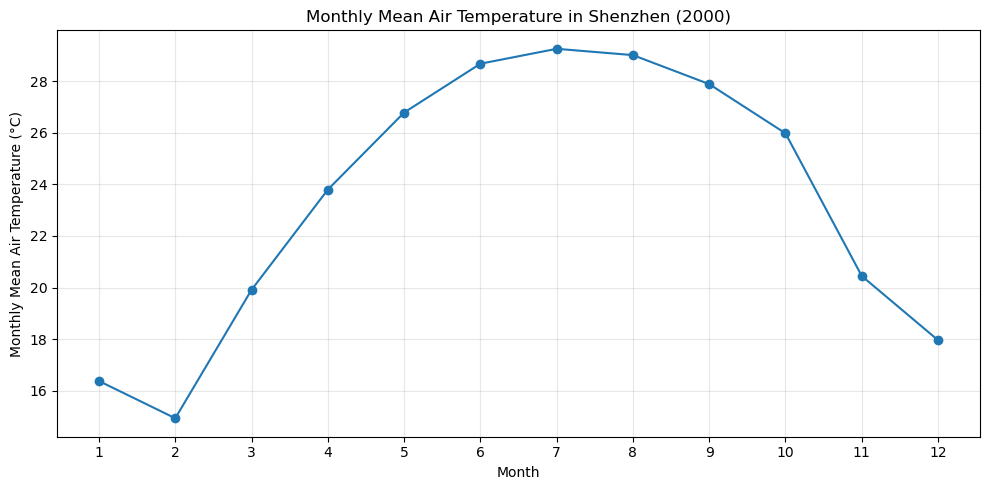

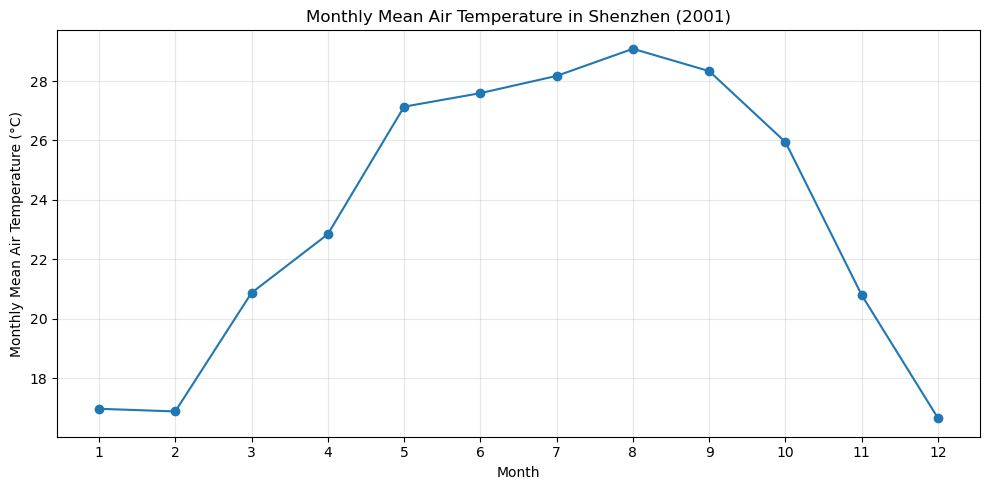

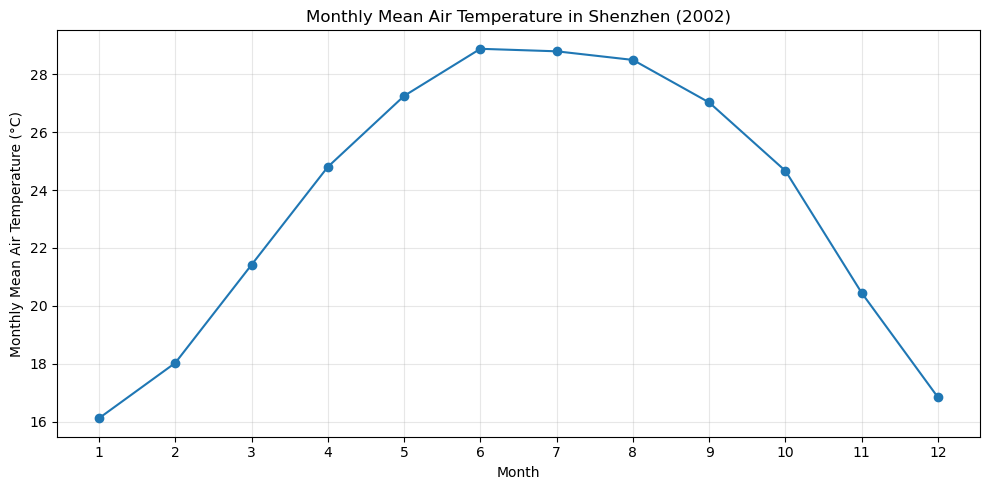

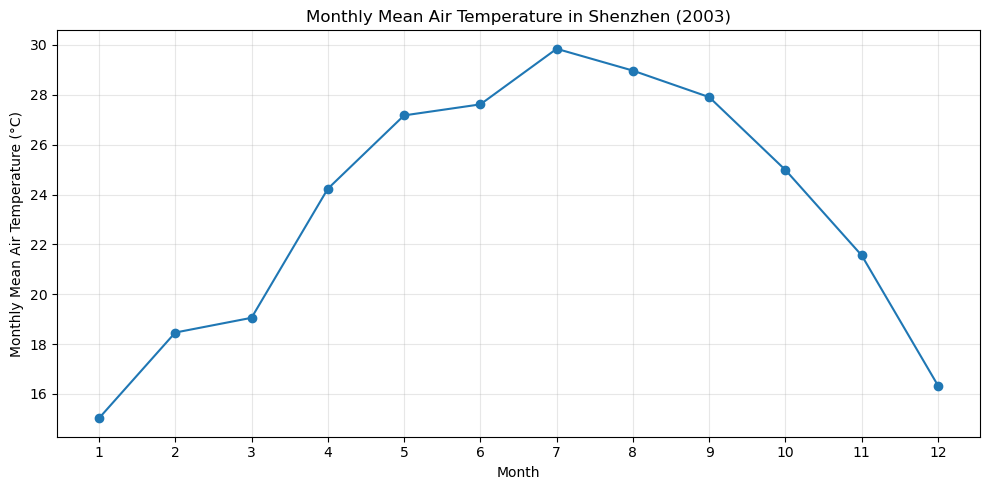

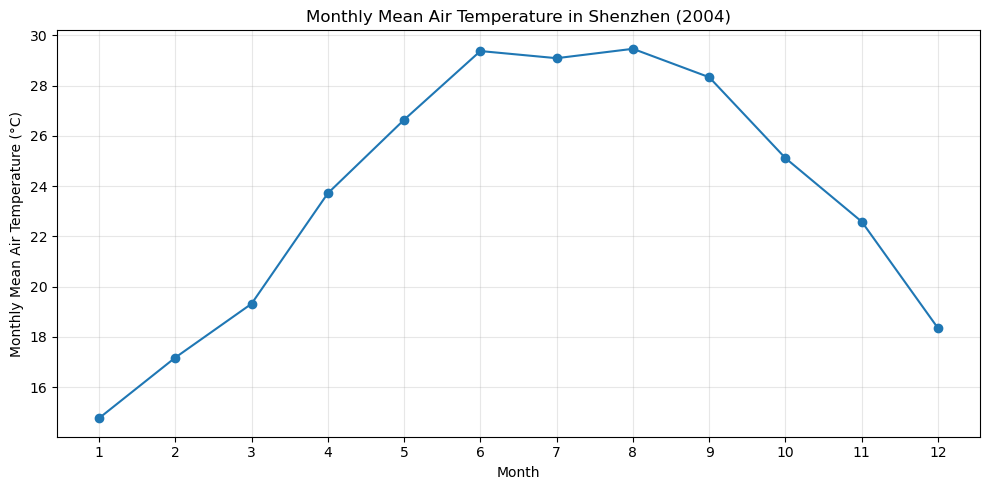

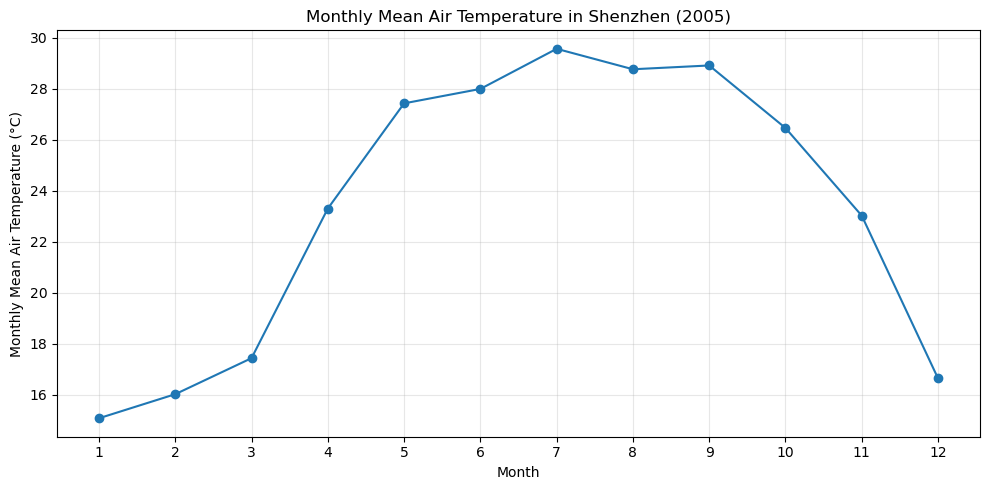

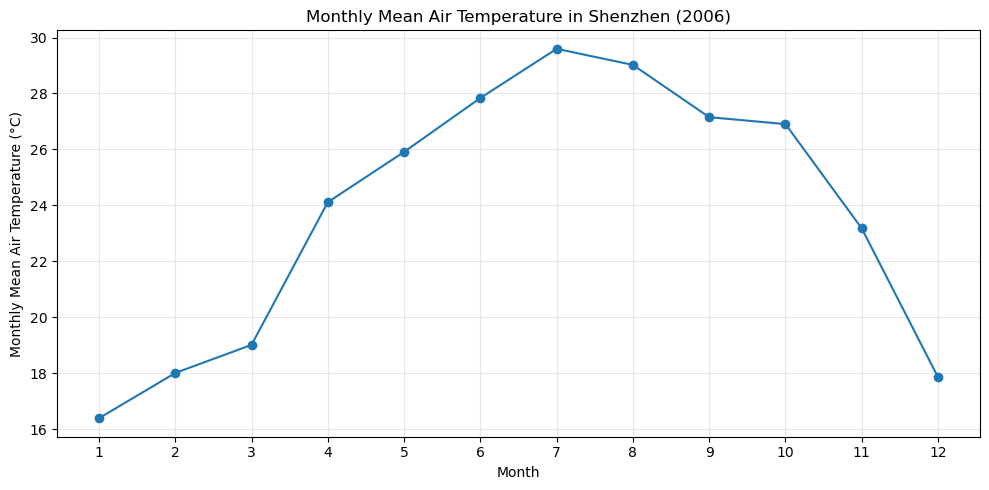

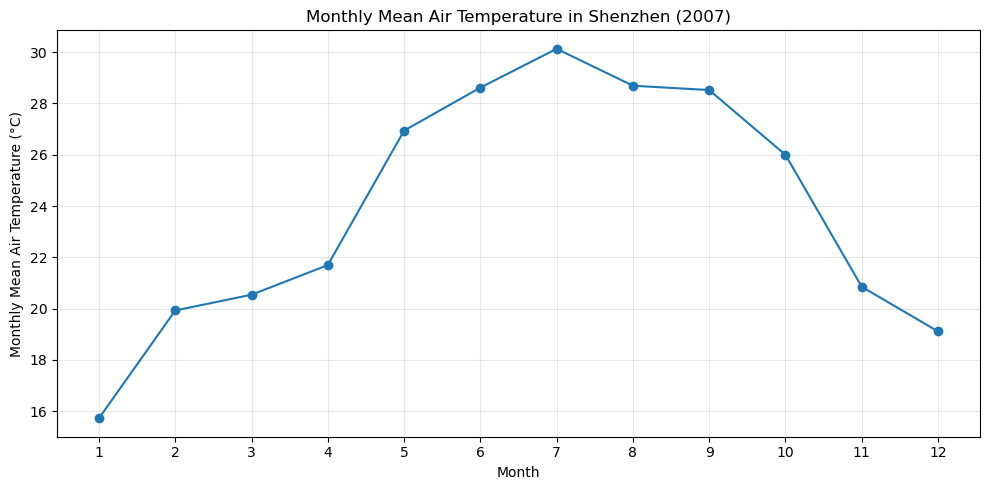

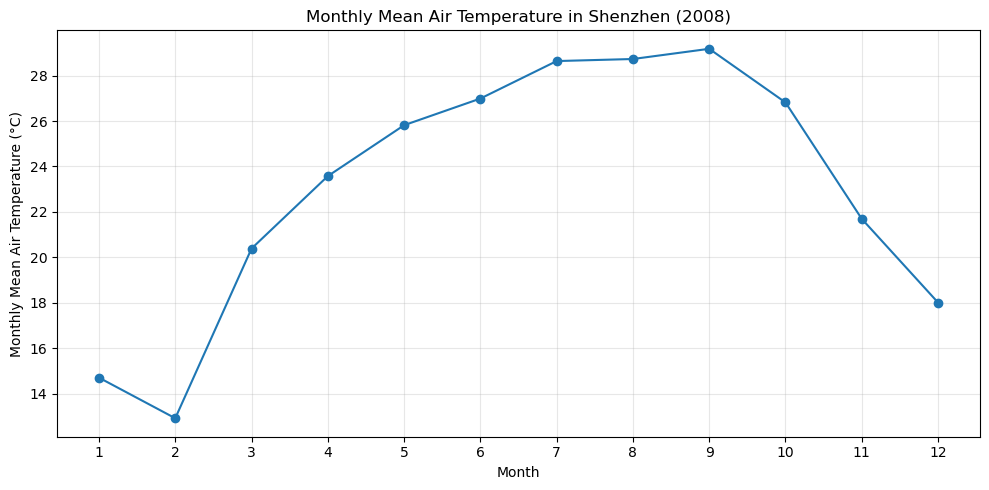

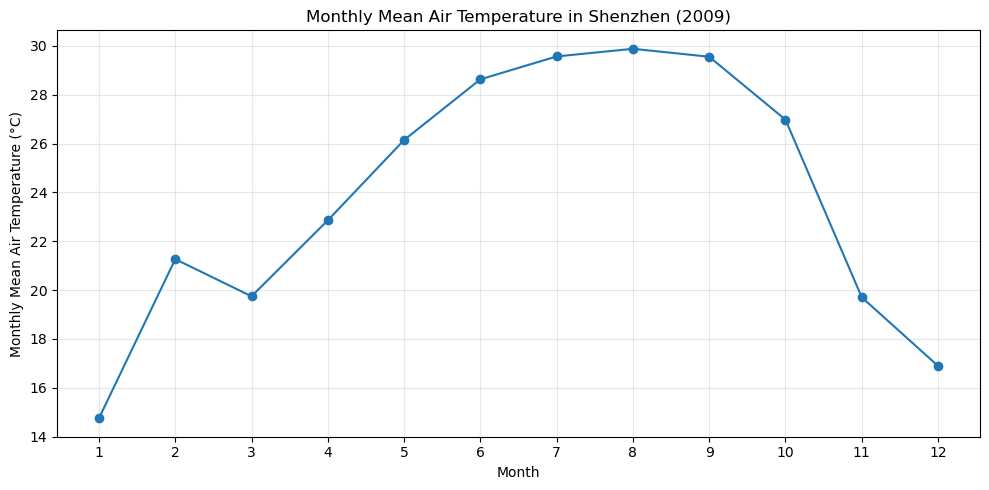

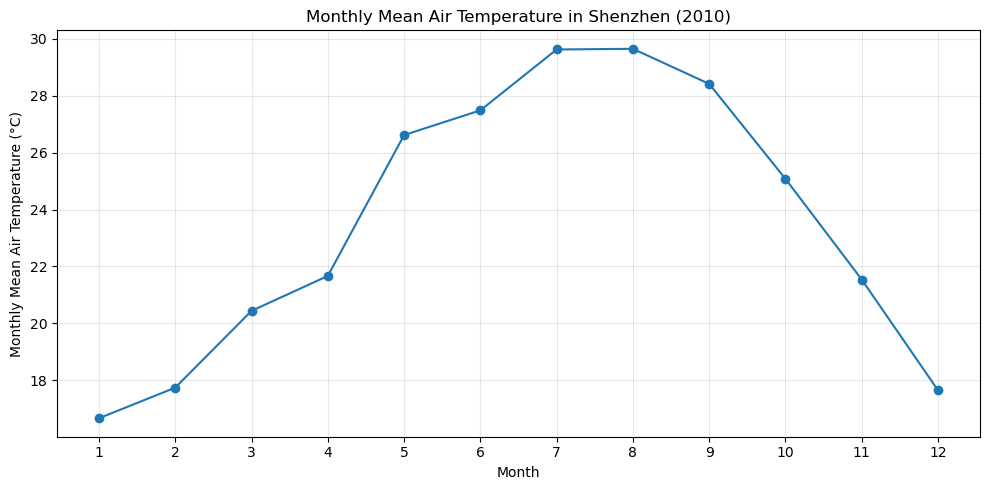

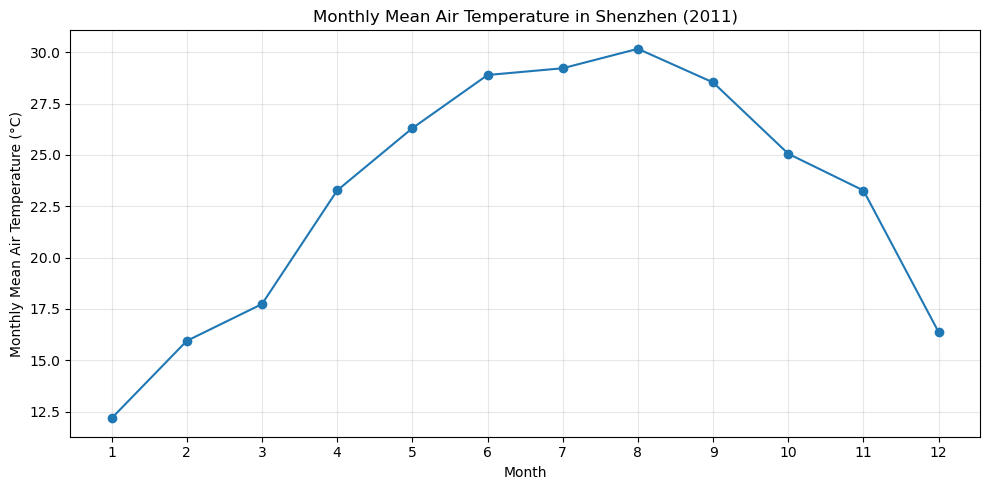

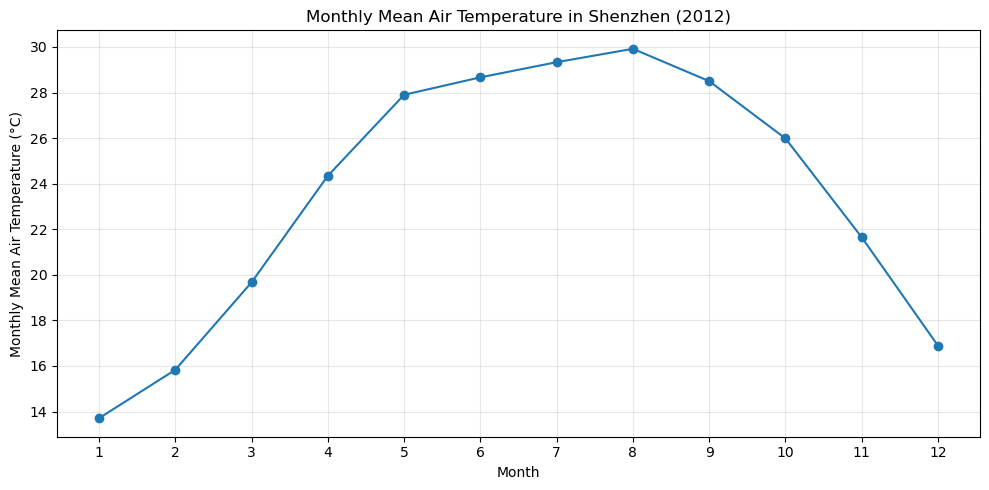

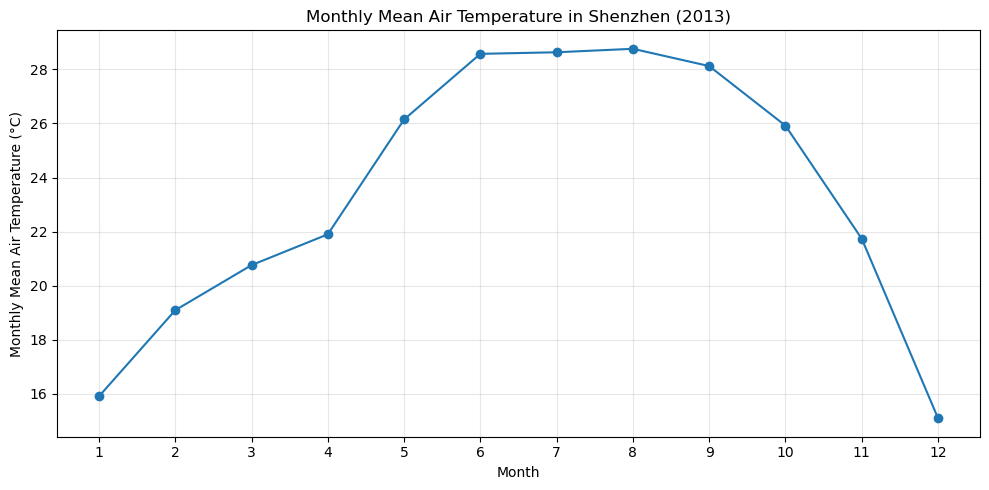

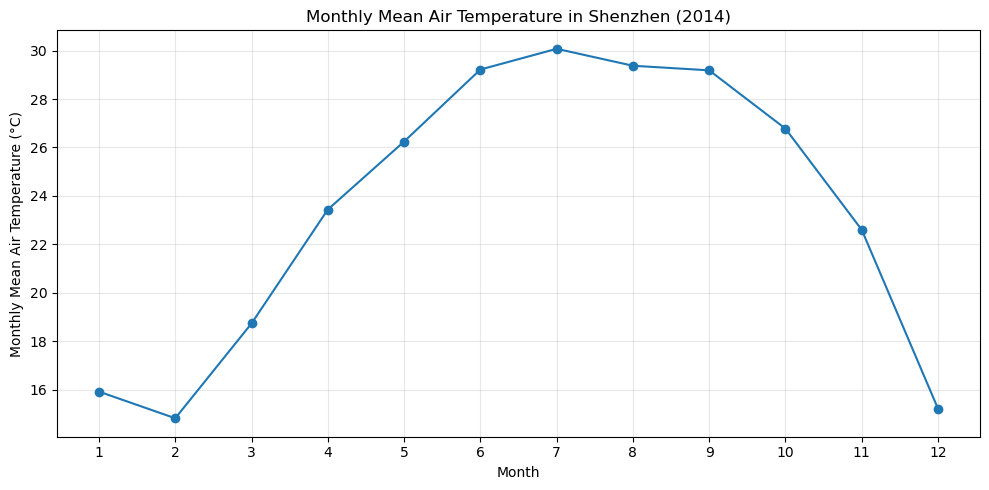

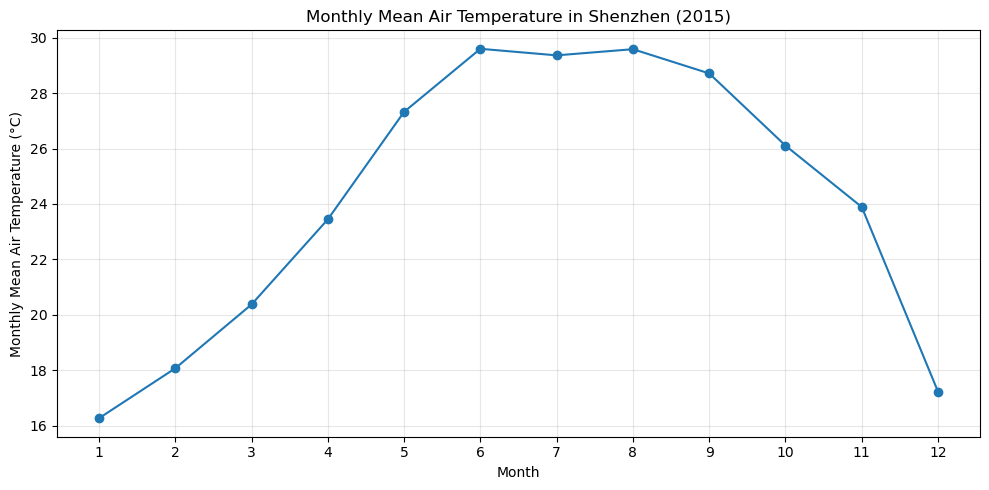

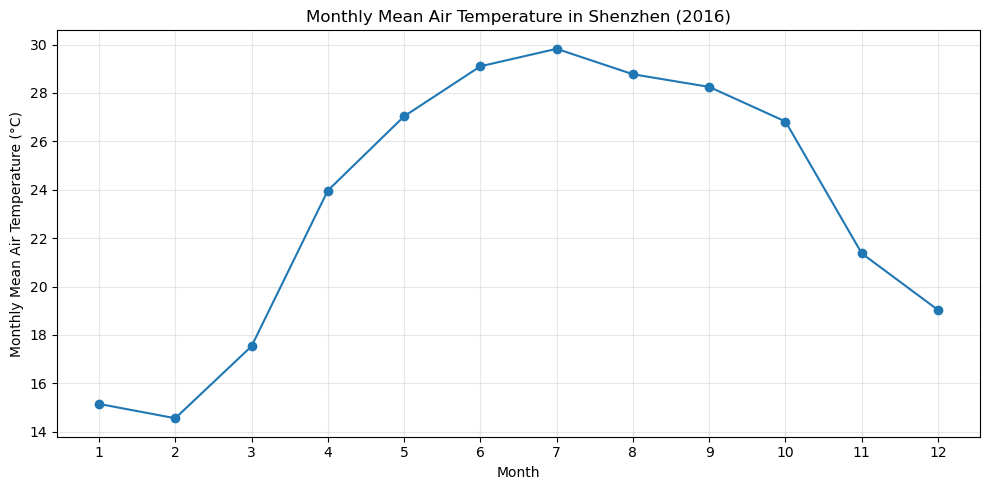

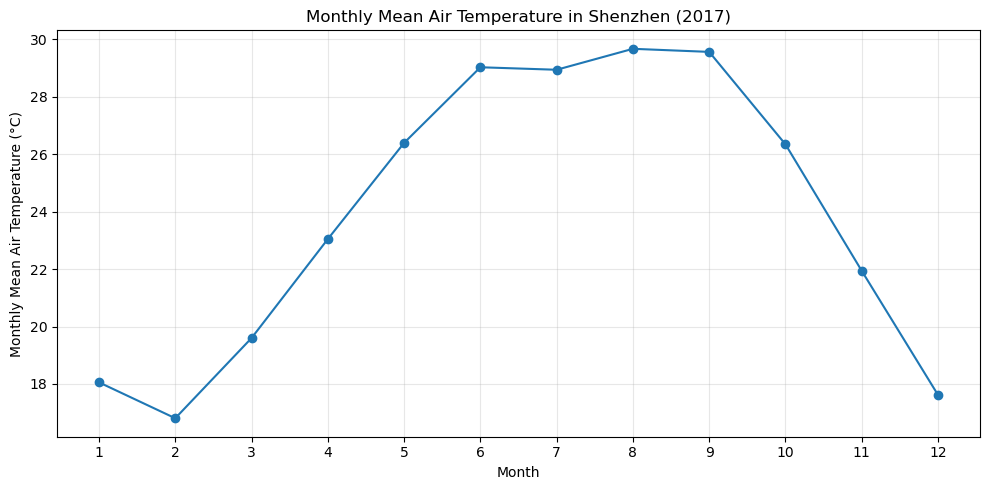

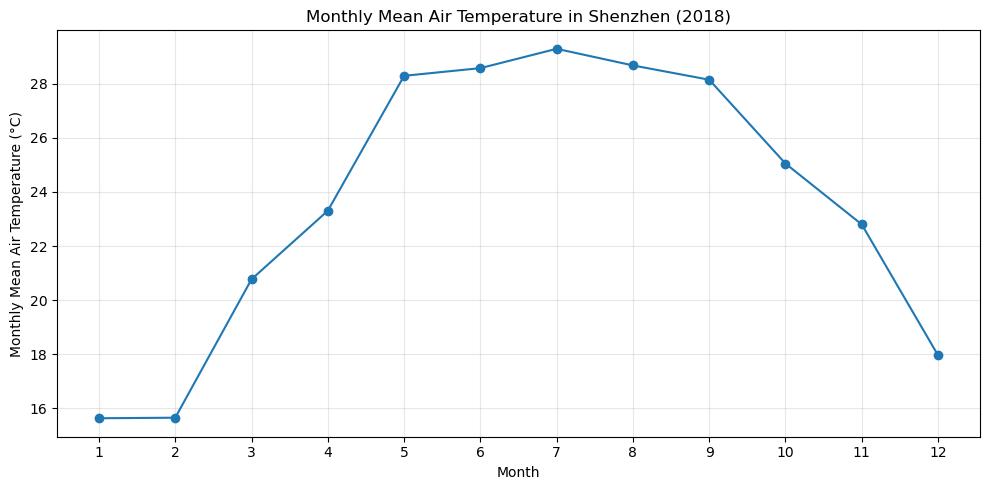

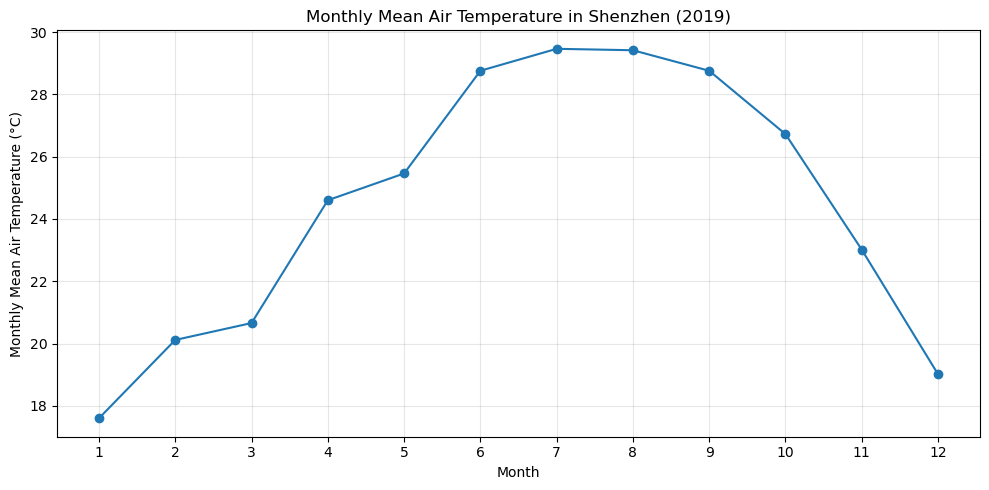

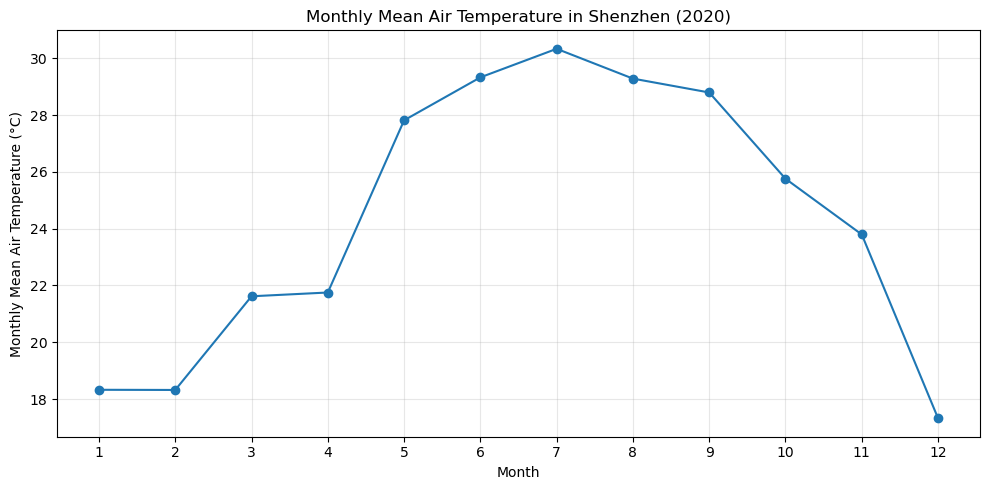

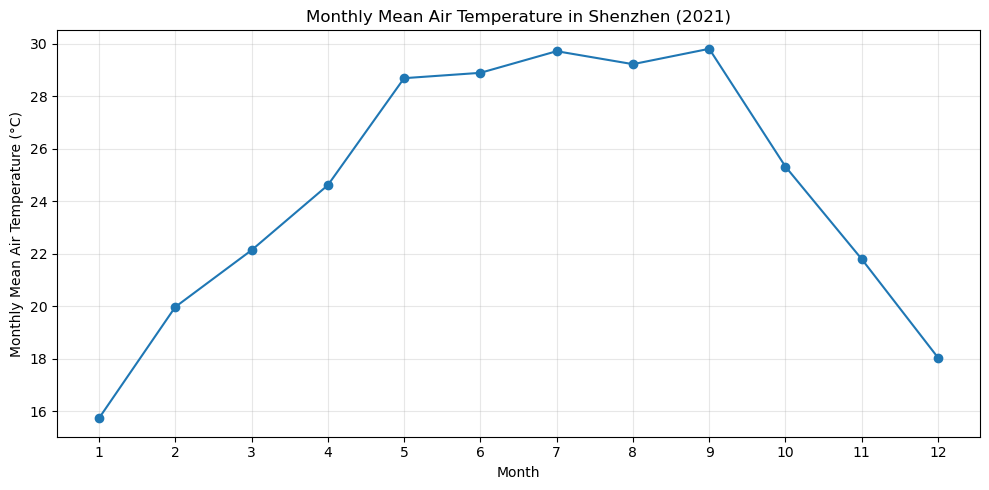

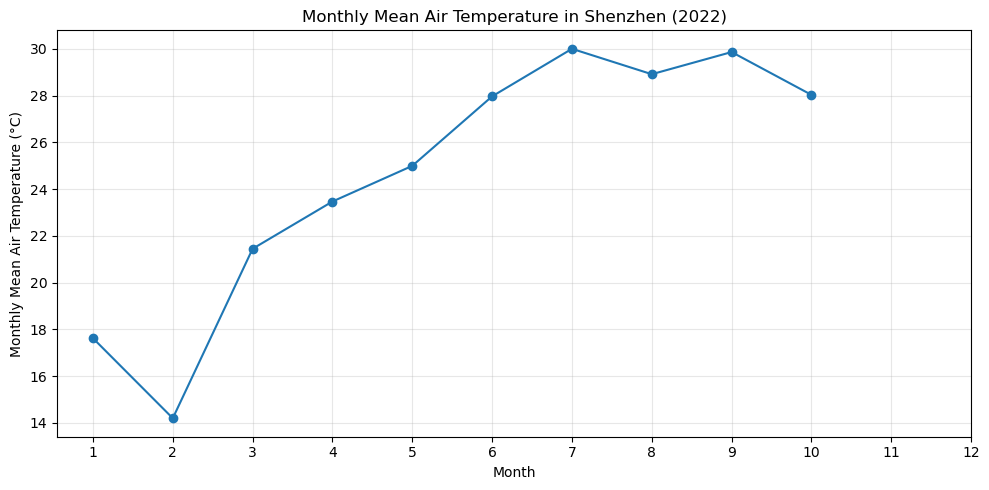

In [33]:
#接第二题可视化

# 使用循环每年绘制一张月平均气温图
for year in range(1998, 2023):

    # 提取当前年份的月平均气温
    yearly_average = monthly_average[
        monthly_average.index.year == year
    ]

    # 创建当前年份的图像
    plt.figure(figsize=(10, 5))

    # 绘制月份与月平均气温的关系
    plt.plot(
        yearly_average.index.month,
        yearly_average.values,
        marker="o",
        linewidth=1.5
    )

    # 设置标题和坐标轴
    plt.title(f"Monthly Mean Air Temperature in Shenzhen ({year})")
    plt.xlabel("Month")
    plt.ylabel("Monthly Mean Air Temperature (°C)")

    # 设置横轴显示 1 到 12 月并添加网格
    plt.xticks(range(1, 13))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [2]:
# 3.1 
# 读取数据并清洗
hc = pd.read_csv(
    "ibtracs.ALL.list.v04r00.csv", 
    usecols=range(17),
    skiprows=[1, 2],
    parse_dates=['ISO_TIME'],
    na_values=['NOT_NAMED', 'NAME'],
    low_memory=False
)

# 将 WMO_WIND 转换为数值类型
hc['WMO_WIND'] = pd.to_numeric(hc['WMO_WIND'], errors='coerce')

# 按 SID 分组，获取最大风速与台风名，并筛选排名前 10 的大台风
top_10 = (
    hc.groupby('SID')
    .agg({'NAME': 'first', 'WMO_WIND': 'max'})
    .sort_values('WMO_WIND', ascending=False)
    .head(10)
)

print(top_10[['NAME', 'WMO_WIND']])

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
2019236N10314    DORIAN     160.0
1988253N12306   GILBERT     160.0
2005289N18282     WILMA     160.0
1935241N23291      None     160.0
1997253N12255     LINDA     160.0
2017242N16333      IRMA     155.0
1998295N12284     MITCH     155.0
2009288N07267      RICK     155.0


In [35]:
#3.2
# 列出风速最强的前 20 个台风及其风速
top_20_winds = (
    hc.groupby('SID')
    .agg({'NAME': 'first', 'WMO_WIND': 'max'})
    .sort_values('WMO_WIND', ascending=False)
    .head(20)
)

print(top_20_winds[['NAME', 'WMO_WIND']])

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
2019236N10314    DORIAN     160.0
1988253N12306   GILBERT     160.0
2005289N18282     WILMA     160.0
1935241N23291      None     160.0
1997253N12255     LINDA     160.0
2017242N16333      IRMA     155.0
1998295N12284     MITCH     155.0
2009288N07267      RICK     155.0
2005261N21290      RITA     155.0
1955265N13307     JANET     150.0
1992230N11325    ANDREW     150.0
2016041S14170   WINSTON     150.0
1977242N27272     ANITA     150.0
2017260N12310     MARIA     150.0
2005236N23285   KATRINA     150.0
1959249N19181     PATSY     150.0
1979238N12324     DAVID     150.0
1994222N11267      JOHN     150.0


In [3]:
#3.3
# 过滤掉缺失值（NaN）以及只包含空格的行
basin_counts = hc['BASIN'].replace(r'^\s*$', pd.NA, regex=True).dropna().value_counts()
print(basin_counts)

BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
Name: count, dtype: int64


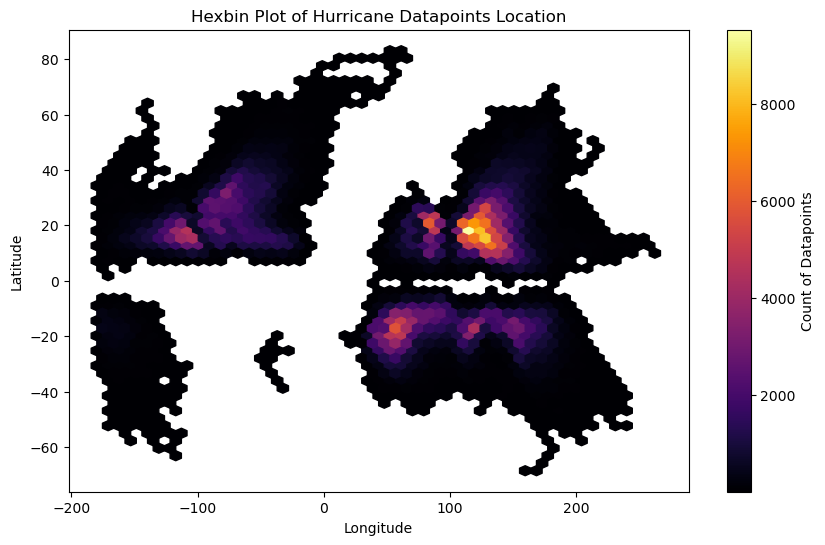

In [37]:
#3.4
# 提取经纬度数据并转换为数值类型
lat_data = pd.to_numeric(hc['LAT'], errors='coerce')
lon_data = pd.to_numeric(hc['LON'], errors='coerce')

# 创建画布并绘制 hexbin图，使用mincnt让数值为0的区域保持空白
plt.figure(figsize=(10, 6))
hb = plt.hexbin(lon_data, lat_data, gridsize=50, cmap='inferno', mincnt=1)

# 添加颜色条和标题标签
plt.colorbar(hb, label='Count of Datapoints')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Hexbin Plot of Hurricane Datapoints Location')
plt.show()

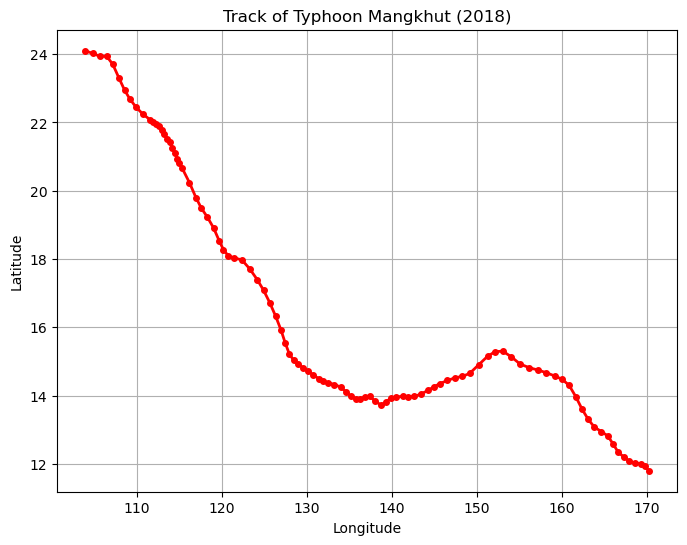

In [38]:
# 3.5 
# 过滤出名称为 MANGKHUT 且年份在 2018 年的数据
mangkhut_df = hc[hc['NAME'] == 'MANGKHUT']
mangkhut_2018 = mangkhut_df[mangkhut_df['ISO_TIME'].dt.year == 2018]

# 转换经纬度为数值
m_lat = pd.to_numeric(mangkhut_2018['LAT'], errors='coerce')
m_lon = pd.to_numeric(mangkhut_2018['LON'], errors='coerce')

# 绘制轨迹图
plt.figure(figsize=(8, 6))
plt.plot(m_lon, m_lat, marker='o', color='red', linestyle='-', linewidth=2, markersize=4)

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Track of Typhoon Mangkhut (2018)')
plt.grid(True)
plt.show()

In [4]:
# 3.6 
# 直接使用 .dt 提取年份
years = hc['ISO_TIME'].dt.year

# 筛选：时间 >= 1970 且 BASIN 在 ['WP', 'EP'] 中
hc_filtered = hc[
    (years >= 1970) & 
    (hc['BASIN'].isin(['WP', 'EP']))
].copy()

print(f"过滤前数据总行数: {len(hc)}")
print(f"过滤后数据总行数: {len(hc_filtered)}")

过滤前数据总行数: 707176
过滤后数据总行数: 176352


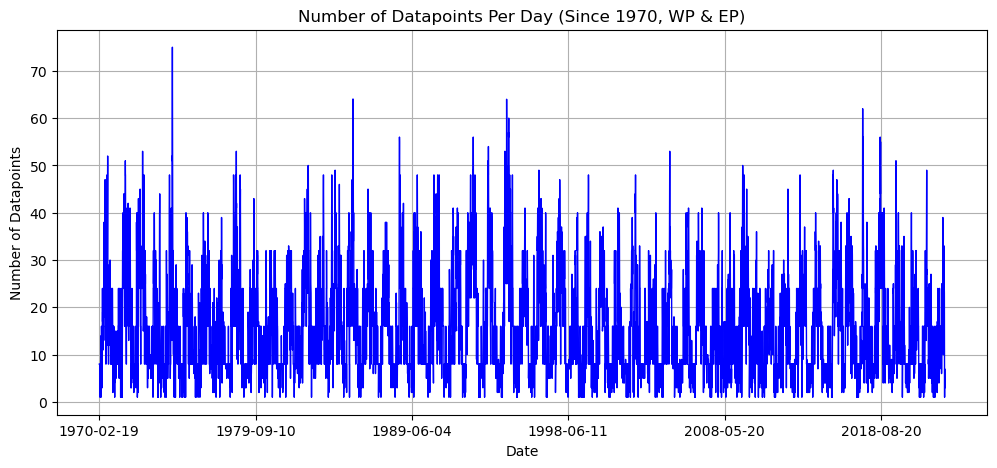

In [40]:
# 3.7 
# 提取出日期部分 (YYYY-MM-DD)
dates = hc_filtered['ISO_TIME'].dt.strftime('%Y-%m-%d')
daily_counts = dates.value_counts().sort_index()

# 绘制每日数据点数量的时间序列折线图
plt.figure(figsize=(12, 5))
daily_counts.plot(kind='line', color='blue', linewidth=1)

plt.xlabel('Date')
plt.ylabel('Number of Datapoints')
plt.title('Number of Datapoints Per Day (Since 1970, WP & EP)')
plt.grid(True)
plt.show()

各 DOY 的平均数据点频次：
DOY
1      1.566038
2      1.358491
3      1.396226
4      1.754717
5      1.981132
         ...   
362    2.981132
363    2.490566
364    1.962264
365    1.754717
366    0.245283
Length: 366, dtype: float64


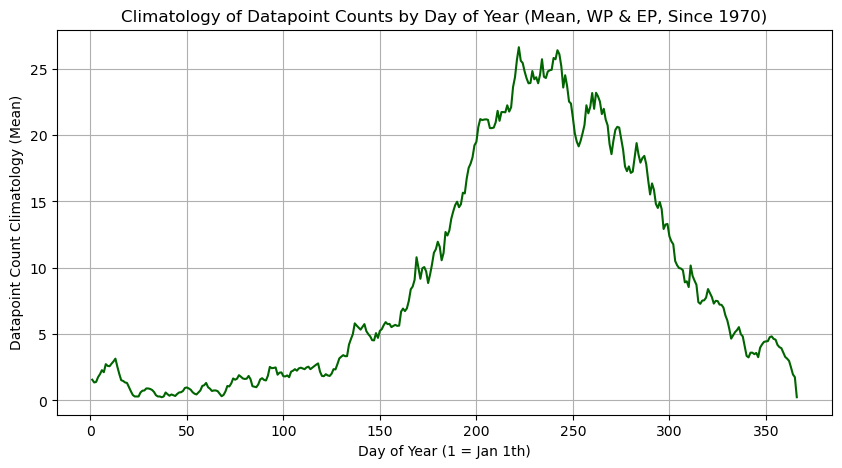

In [5]:
# 3.8 
# 确保 ISO_TIME 为 datetime 类型，并提取年份和一年中的第几天
hc_filtered['Year'] = hc_filtered['ISO_TIME'].dt.year
hc_filtered['DOY'] = hc_filtered['ISO_TIME'].dt.dayofyear

# 先按年份和 Day of Year 统计每年每一天的频次，然后求所有年份的平均值 (mean)
doy_yearly_counts = hc_filtered.groupby(['Year', 'DOY']).size().unstack(fill_value=0)
doy_climatology = doy_yearly_counts.mean(axis=0).sort_index()

# 打印数值结果
print("各 DOY 的平均数据点频次：")
print(doy_climatology)

# 绘制气候态分布图
plt.figure(figsize=(10, 5))
doy_climatology.plot(kind='line', color='darkgreen', linewidth=1.5)

plt.xlabel('Day of Year (1 = Jan 1th)')
plt.ylabel('Datapoint Count Climatology (Mean)')
plt.title('Climatology of Datapoint Counts by Day of Year (Mean, WP & EP, Since 1970)')
plt.grid(True)
plt.show()

每日数据点数量：
ISO_TIME
1970-02-19    8
1970-02-20    8
1970-02-21    8
1970-02-22    8
1970-02-23    8
             ..
2022-10-04    9
2022-10-05    7
2022-10-09    1
2022-10-10    7
2022-10-12    3
Name: count, Length: 10817, dtype: int64

每日数据点数量异常值（实际值 - 历年同一天平均值）：
ISO_TIME
1970-02-19     1.500000
1970-02-20     0.000000
1970-02-21     0.833333
1970-02-22     1.400000
1970-02-23     2.600000
                ...    
2022-10-04    -8.980769
2022-10-05   -11.693878
2022-10-09   -17.301887
2022-10-10   -12.769231
2022-10-12   -15.269231
Length: 10817, dtype: float64


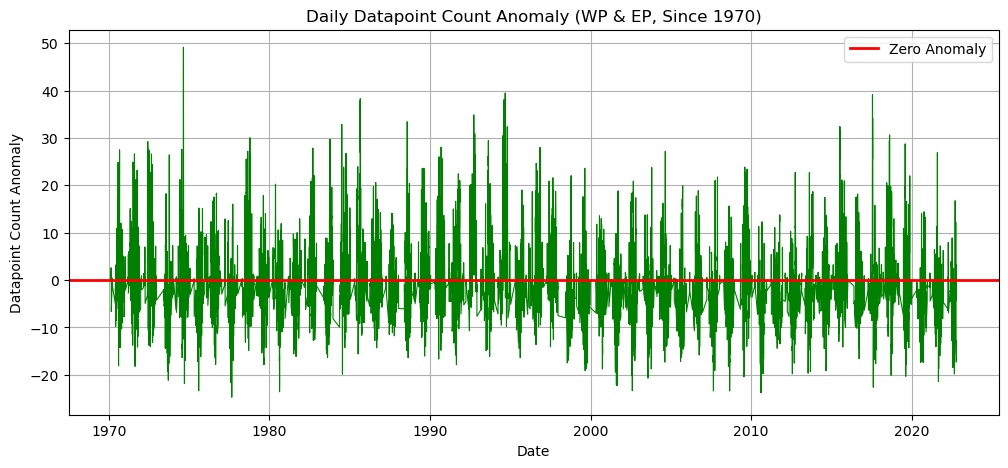

In [6]:
# 3.9 
# 获取每日实际数据点数量（通过 .dt.strftime 转换为日期字符串）
daily_counts = hc_filtered['ISO_TIME'].dt.strftime('%Y-%m-%d').value_counts().sort_index()

# 获取每一天的 Day of Year 数值
date_dt = pd.to_datetime(daily_counts.index)
doy_series = date_dt.dayofyear

# 计算历年同一天的平均值
doy_mean = daily_counts.groupby(doy_series).mean()
expected_counts = doy_series.map(doy_mean)

# 计算异常值 (实际值 - 均值)
anomaly = daily_counts - expected_counts

# 打印数值结果
print("每日数据点数量：")
print(daily_counts)
print("\n每日数据点数量异常值（实际值 - 历年同一天平均值）：")
print(anomaly)

# 绘制异常值时间序列图
plt.figure(figsize=(12, 5))
plt.plot(date_dt, anomaly, color='green', linewidth=0.8)
# 添加一条 0 值线增强对比
plt.axhline(0, color='red', linewidth=2, label='Zero Anomaly')
plt.xlabel('Date')
plt.ylabel('Datapoint Count Anomaly')
plt.title('Daily Datapoint Count Anomaly (WP & EP, Since 1970)')
plt.legend()
plt.grid(True)
plt.show()

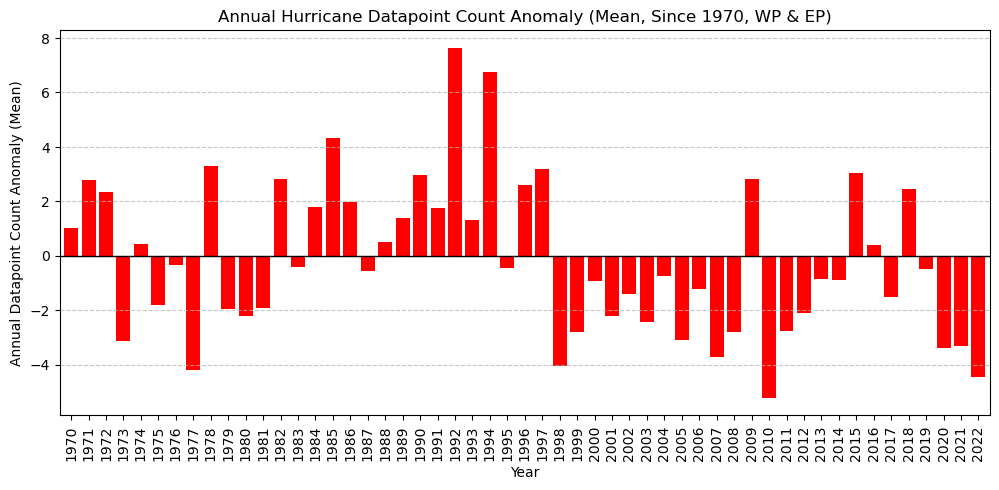

年度平均异常值最高（台风最活跃）的前5个年份:
ISO_TIME
1992    7.645086
1994    6.769985
1985    4.338109
1978    3.298956
1997    3.195031
dtype: float64
年度平均异常值最低（台风最沉寂）的前5个年份:
ISO_TIME
2010   -5.217217
2022   -4.456293
1977   -4.192921
1998   -4.035779
2007   -3.731739
dtype: float64


In [43]:
# 3.10 
# 将异常值信息格式统一并按年求平均值 (mean)
anomaly.index = pd.to_datetime(anomaly.index)
annual_anomaly = anomaly.resample('YE').mean()

# 将索引格式化为纯年份字符串
annual_anomaly.index = annual_anomaly.index.strftime('%Y')

# 3. 绘制年度异常值柱状图
plt.figure(figsize=(12, 5))
colors = ['red']
annual_anomaly.plot(kind='bar', color=colors, width=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.xlabel('Year')
plt.ylabel('Annual Datapoint Count Anomaly (Mean)')
plt.title('Annual Hurricane Datapoint Count Anomaly (Mean, Since 1970, WP & EP)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# 4. 打印排名前几位的异常年份
print("年度平均异常值最高（台风最活跃）的前5个年份:")
print(annual_anomaly.sort_values(ascending=False).head(5))
print("年度平均异常值最低（台风最沉寂）的前5个年份:")
print(annual_anomaly.sort_values(ascending=True).head(5))

In [8]:
# 4.1 
df = pd.read_csv(
    "US1WIDN0005.csv",
    usecols=[
        "DATE",
        "PRCP", "PRCP_ATTRIBUTES",
        "SNOW", "SNOW_ATTRIBUTES",
        "EMXP", "EMXP_ATTRIBUTES",
        "EMSN", "EMSN_ATTRIBUTES",
        "EMSD", "EMSD_ATTRIBUTES",
        "DP01", "DP10", "DP1X",
        "DSNW", "DSND"
    ]
)
print("清洗前数据量：", len(df))

# 删除 PRCP_ATTRIBUTES 为空的行
df = df.dropna(subset=["PRCP_ATTRIBUTES"])

# 拆分属性字段，提取第三位质量标记，删除第三位有质量标记的行
flags = df["PRCP_ATTRIBUTES"].str.split(",", expand=True)
df = df[flags[2].fillna("").str.strip() == ""]

# 删除日期或降水量缺失的行
df = df.dropna(subset=["DATE", "PRCP"])

# 转换日期格式（原始数据为年-月）
df["DATE"] = pd.to_datetime(
    df["DATE"], format="%Y-%m", errors="coerce"
)
df = df.dropna(subset=["DATE"])

# 删除重复月份
df = df.drop_duplicates(subset=["DATE"])

# 日期展示为年-月形式
df["DATE"] = df["DATE"].dt.strftime("%Y-%m")

print("清洗后数据量：", len(df))



清洗前数据量： 140
清洗后数据量： 137


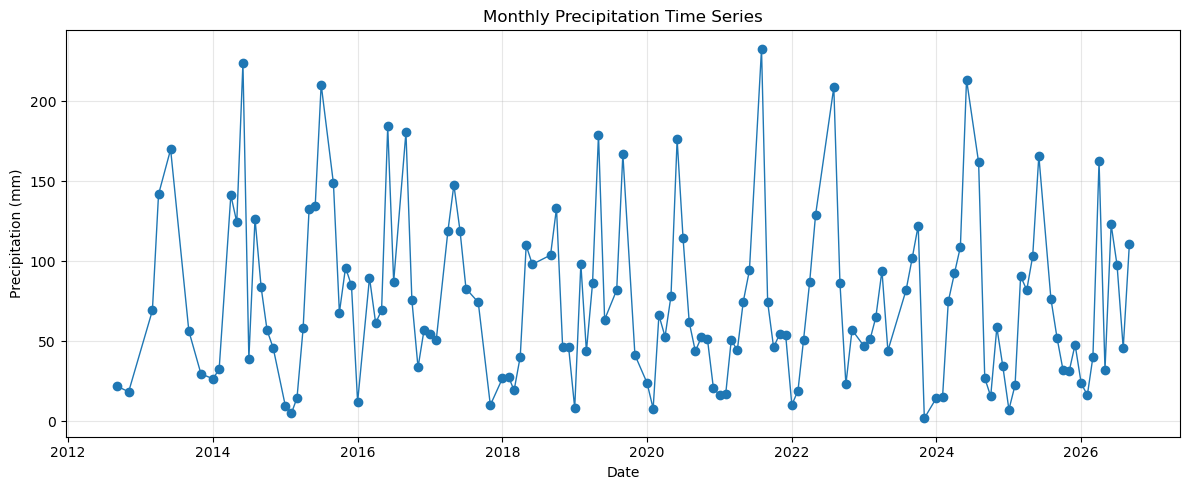

In [10]:
#4.2
# 绘制时间序列图
df["DATE"] = pd.to_datetime(df["DATE"], format="%Y-%m")
plt.figure(figsize=(12, 5))

plt.plot(df["DATE"], df["PRCP"], marker="o", linewidth=1)

plt.title("Monthly Precipitation Time Series")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

观测数量: 137
均值: 74.94
中位数 Q2: 61.4
第一四分位数 Q1: 33.6
第三四分位数 Q3: 102.1
四分位距 IQR: 68.5
最小值: 1.9
最大值: 232.6
标准差: 52.93


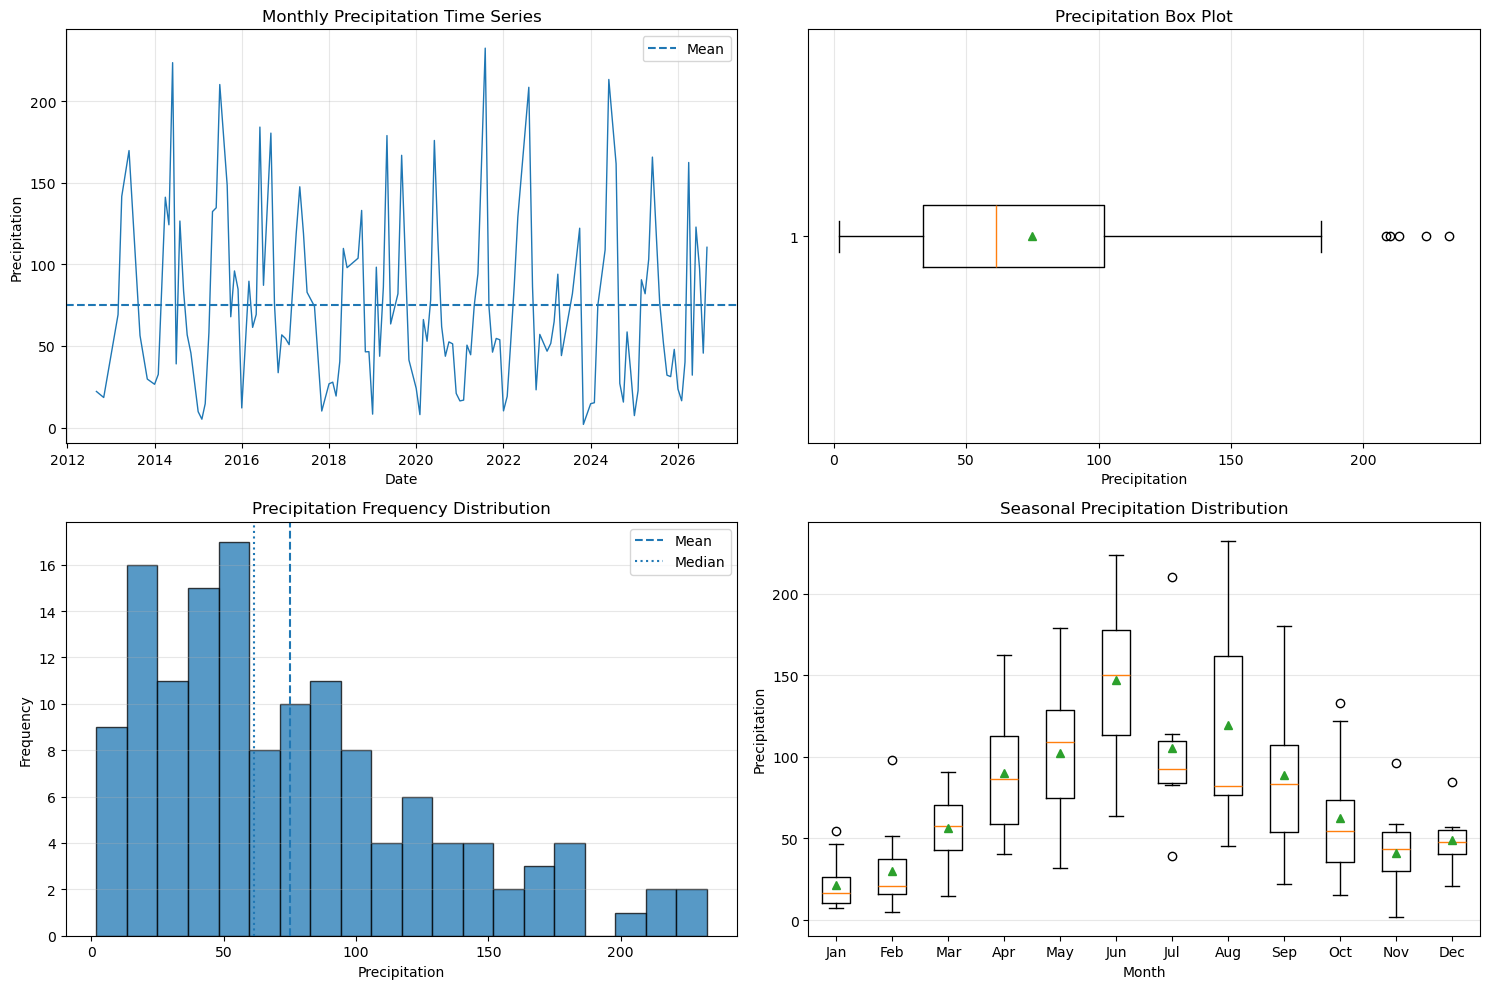

In [12]:
#4.3
#数据准备
df["DATE"] = pd.to_datetime(df["DATE"], format="%Y-%m")
df["PRCP"] = pd.to_numeric(df["PRCP"], errors="coerce")
df = df.sort_values("DATE")
prcp = df["PRCP"]

# 2. 计算统计指标
Q1 = prcp.quantile(0.25)
Q2 = prcp.quantile(0.50)
Q3 = prcp.quantile(0.75)
IQR = Q3 - Q1

print("观测数量:", prcp.count())
print("均值:", round(prcp.mean(), 2))
print("中位数 Q2:", round(Q2, 2))
print("第一四分位数 Q1:", round(Q1, 2))
print("第三四分位数 Q3:", round(Q3, 2))
print("四分位距 IQR:", round(IQR, 2))
print("最小值:", round(prcp.min(), 2))
print("最大值:", round(prcp.max(), 2))
print("标准差:", round(prcp.std(), 2))

#可视化
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 图1：降水量时间序列
axes[0, 0].plot(df["DATE"], prcp, linewidth=1)
axes[0, 0].axhline(
    prcp.mean(), linestyle="--", linewidth=1.5,
    label="Mean"
)
axes[0, 0].set_title("Monthly Precipitation Time Series")
axes[0, 0].set_xlabel("Date")
axes[0, 0].set_ylabel("Precipitation")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 图2：总体箱线图
axes[0, 1].boxplot(prcp, vert=False, showmeans=True)
axes[0, 1].set_title("Precipitation Box Plot")
axes[0, 1].set_xlabel("Precipitation")
axes[0, 1].grid(axis="x", alpha=0.3)

# 图3：降水量频率分布
axes[1, 0].hist(prcp, bins=20, edgecolor="black", alpha=0.75)
axes[1, 0].axvline(
    prcp.mean(), linestyle="--", linewidth=1.5,
    label="Mean"
)
axes[1, 0].axvline(
    prcp.median(), linestyle=":", linewidth=1.5,
    label="Median"
)
axes[1, 0].set_title("Precipitation Frequency Distribution")
axes[1, 0].set_xlabel("Precipitation")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", alpha=0.3)

# 图4：不同月份的降水量箱线图
df["Month"] = df["DATE"].dt.month

monthly_data = [
    df.loc[df["Month"] == month, "PRCP"].dropna()
    for month in range(1, 13)
]

axes[1, 1].boxplot(
    monthly_data,
    tick_labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    showmeans=True
)
axes[1, 1].set_title("Seasonal Precipitation Distribution")
axes[1, 1].set_xlabel("Month")
axes[1, 1].set_ylabel("Precipitation")
axes[1, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()